
# Punto 4. Red de memoria asociativa: recuperación de patrones binarios

## 1. Introducción

En este ejercicio se implementa una red de memoria asociativa capaz de almacenar y recuperar patrones binarios mediante la minimización de una función de energía.

Se utilizarán dos patrones correspondientes a las letras **J** y **H**, representados como imágenes de $8\times8$ píxeles. Cada píxel tendrá un valor de $+1$ si está activo y $-1$ si está inactivo.

La red estará formada por $N=64$ neuronas y almacenará $P=2$ patrones, organizados en una matriz:

$$
X\in\{-1,+1\}^{2\times64}.
$$

La función de energía del sistema es:

$$
E(\mathbf q)=
\frac12\sum_{i=1}^{N}q_i^2
-\frac1\beta
\ln\left[
\sum_{\mu=1}^{P}
\exp\left(
\beta\sum_{i=1}^{N}x_{\mu i}q_i
\right)
\right].
$$

A partir del descenso de gradiente, para $\alpha=1$, la regla de actualización es:

$$
\mathbf q^{(t+1)}
=
X^\mathsf{T}
\operatorname{softmax}
\left(\beta X\mathbf q^{(t)}\right).
$$

El objetivo es estudiar la capacidad de la red para recuperar los patrones almacenados cuando se presentan imágenes perturbadas, y analizar cómo influyen el porcentaje de píxeles modificados y el parámetro $\beta$ en la recuperación.

Inicialmente se construirán y visualizarán las letras J y H, verificando su representación binaria y las dimensiones de la matriz de patrones.


DIMENSIONES DEL SISTEMA
----------------------------------------
Número de patrones P: 2
Número de neuronas N: 64
Dimensiones de X: (2, 64)
Valores presentes: [-1.  1.]

Verificación correcta: patrones binarios de 8x8.


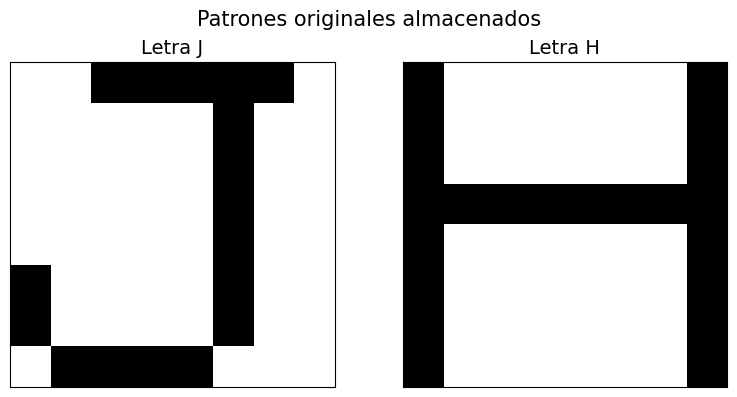

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Reproducibilidad de los experimentos
np.random.seed(42)

# =====================================================
# 1. DEFINICIÓN DE LOS PATRONES BINARIOS
# =====================================================

# Letra J: 1 = píxel activo, -1 = píxel inactivo
J = np.array([
    [-1, -1,  1,  1,  1,  1,  1, -1],
    [-1, -1, -1, -1, -1,  1, -1, -1],
    [-1, -1, -1, -1, -1,  1, -1, -1],
    [-1, -1, -1, -1, -1,  1, -1, -1],
    [-1, -1, -1, -1, -1,  1, -1, -1],
    [ 1, -1, -1, -1, -1,  1, -1, -1],
    [ 1, -1, -1, -1, -1,  1, -1, -1],
    [-1,  1,  1,  1,  1, -1, -1, -1]
], dtype=float)

# Letra H
H = np.array([
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1,  1,  1,  1,  1,  1,  1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1],
    [ 1, -1, -1, -1, -1, -1, -1,  1]
], dtype=float)

# =====================================================
# 2. CONSTRUCCIÓN DE LA MATRIZ DE PATRONES
# =====================================================

# Convertimos cada imagen 8x8 en un vector de 64 elementos
J_vector = J.flatten()
H_vector = H.flatten()

# Matriz de patrones: P x N = 2 x 64
X = np.vstack([J_vector, H_vector])

P, N = X.shape

# =====================================================
# 3. VERIFICACIÓN
# =====================================================

print("DIMENSIONES DEL SISTEMA")
print("-" * 40)
print(f"Número de patrones P: {P}")
print(f"Número de neuronas N: {N}")
print(f"Dimensiones de X: {X.shape}")
print(f"Valores presentes: {np.unique(X)}")

assert X.shape == (2, 64)
assert np.all(np.isin(X, [-1, 1]))

print("\nVerificación correcta: patrones binarios de 8x8.")

# =====================================================
# 4. VISUALIZACIÓN DE LOS PATRONES
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, patron, nombre in zip(
    axes, [J, H], ["Letra J", "Letra H"]
):
    ax.imshow(
        patron,
        cmap="gray_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(nombre, fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    "Patrones originales almacenados",
    fontsize=15
)

plt.tight_layout()
plt.show()



## 2. Implementación de la energía y la regla de actualización

La recuperación de los patrones almacenados se realiza mediante la minimización de la función de energía:

$$
E(\mathbf q)=
\frac12\sum_{i=1}^{N}q_i^2
-\frac1\beta
\ln\left[
\sum_{\mu=1}^{P}
\exp\left(
\beta\sum_{i=1}^{N}x_{\mu i}q_i
\right)
\right].
$$

El primer término depende de la magnitud del estado de la red, mientras que el segundo favorece los estados que presentan una mayor similitud con alguno de los patrones almacenados.

Para calcular la contribución de cada memoria, se utiliza la función softmax:

$$
p_\mu(\mathbf q)=
\frac{\exp(\beta\mathbf x^\mu\cdot\mathbf q)}
{\sum_{\nu=1}^{P}\exp(\beta\mathbf x^\nu\cdot\mathbf q)}.
$$

Estos pesos satisfacen:

$$
p_\mu\geq0,
\qquad
\sum_{\mu=1}^{P}p_\mu=1.
$$

El gradiente de la energía es:

$$
\nabla E(\mathbf q)
=
\mathbf q-X^\mathsf{T}\mathbf p(\mathbf q).
$$

Aplicando descenso de gradiente con $\alpha=1$, se obtiene:

$$
\boxed{
\mathbf q^{(t+1)}
=
X^\mathsf{T}\operatorname{softmax}
\left(\beta X\mathbf q^{(t)}\right)
}
$$

En cada iteración, la red calcula la similitud entre el estado actual y las memorias almacenadas. Después asigna pesos a los patrones y construye un nuevo estado como una combinación ponderada de ellos.

Para evitar problemas numéricos al calcular las exponenciales, se implementarán versiones estables de softmax y log-sum-exp.

También se calculará la energía durante las iteraciones para estudiar si la red evoluciona hacia un estado estable.


In [2]:

import numpy as np

# ============================================================
# 1. FUNCIÓN SOFTMAX NUMÉRICAMENTE ESTABLE
# ============================================================

def softmax_estable(z):
    """
    Calcula softmax evitando desbordamiento numérico.
    """
    z = np.asarray(z, dtype=float)

    z_max = np.max(z)
    exp_z = np.exp(z - z_max)

    return exp_z / np.sum(exp_z)


# ============================================================
# 2. FUNCIÓN LOG-SUM-EXP ESTABLE
# ============================================================

def logsumexp_estable(z):
    """
    Calcula log(sum(exp(z))) de manera estable.
    """
    z = np.asarray(z, dtype=float)

    z_max = np.max(z)

    return z_max + np.log(
        np.sum(np.exp(z - z_max))
    )


# ============================================================
# 3. PESOS DE RECUPERACIÓN
# ============================================================

def calcular_pesos(q, X, beta):
    """
    Calcula los pesos de los patrones almacenados.

    q: estado de la red, dimensión (N,)
    X: matriz de patrones, dimensión (P, N)
    beta: parámetro de selectividad
    """
    q = np.asarray(q, dtype=float).reshape(-1)

    if beta <= 0:
        raise ValueError("beta debe ser positivo.")

    similitudes = X @ q

    pesos = softmax_estable(beta * similitudes)

    return pesos


# ============================================================
# 4. FUNCIÓN DE ENERGÍA
# ============================================================

def energia(q, X, beta):
    """
    E(q) = 0.5 * ||q||²
           - (1/beta) * logsumexp(beta * X @ q)
    """
    q = np.asarray(q, dtype=float).reshape(-1)

    if beta <= 0:
        raise ValueError("beta debe ser positivo.")

    termino_cuadratico = 0.5 * np.dot(q, q)

    similitudes = X @ q

    termino_memoria = (
        logsumexp_estable(beta * similitudes) / beta
    )

    return termino_cuadratico - termino_memoria


# ============================================================
# 5. GRADIENTE ANALÍTICO DE LA ENERGÍA
# ============================================================

def gradiente_energia(q, X, beta):
    """
    Gradiente E(q) = q - X.T @ pesos
    """
    q = np.asarray(q, dtype=float).reshape(-1)

    pesos = calcular_pesos(q, X, beta)

    return q - X.T @ pesos


# ============================================================
# 6. REGLA DE ACTUALIZACIÓN
# ============================================================

def actualizar_estado(q, X, beta, alpha=1.0):
    """
    Realiza un paso de descenso de gradiente.

    q_nuevo = q - alpha * gradiente E(q)
    """
    q = np.asarray(q, dtype=float).reshape(-1)

    gradiente = gradiente_energia(q, X, beta)

    q_nuevo = q - alpha * gradiente

    return q_nuevo


# ============================================================
# 7. PRUEBA CON UN PATRÓN ALMACENADO
# ============================================================

q_inicial = J_vector.copy()

beta_prueba = 1.0
alpha_prueba = 1.0

energia_inicial = energia(
    q_inicial, X, beta_prueba
)

pesos_iniciales = calcular_pesos(
    q_inicial, X, beta_prueba
)

q_nuevo = actualizar_estado(
    q_inicial, X, beta_prueba, alpha_prueba
)

energia_nueva = energia(
    q_nuevo, X, beta_prueba
)

print("PRUEBA DE LAS FUNCIONES FUNDAMENTALES")
print("=" * 50)

print(f"Dimensión del estado inicial: {q_inicial.shape}")
print(f"Dimensión del nuevo estado: {q_nuevo.shape}")

print("\nPesos de recuperación:")
print(f"Peso de la letra J: {pesos_iniciales[0]:.8f}")
print(f"Peso de la letra H: {pesos_iniciales[1]:.8f}")

print(f"\nSuma de los pesos: {pesos_iniciales.sum():.8f}")

print(f"\nEnergía inicial: {energia_inicial:.8f}")
print(f"Energía después de un paso: {energia_nueva:.8f}")

print(
    f"Norma del gradiente inicial: "
    f"{np.linalg.norm(gradiente_energia(q_inicial, X, beta_prueba)):.8e}"
)

# Comprobaciones
assert np.isclose(pesos_iniciales.sum(), 1.0)
assert q_nuevo.shape == (64,)
assert np.all(np.isfinite(q_nuevo))
assert np.all(np.abs(q_nuevo) <= 1.0 + 1e-12)

print("\nTodas las comprobaciones fueron satisfactorias.")


PRUEBA DE LAS FUNCIONES FUNDAMENTALES
Dimensión del estado inicial: (64,)
Dimensión del nuevo estado: (64,)

Pesos de recuperación:
Peso de la letra J: 1.00000000
Peso de la letra H: 0.00000000

Suma de los pesos: 1.00000000

Energía inicial: -32.00000000
Energía después de un paso: -32.00000000
Norma del gradiente inicial: 0.00000000e+00

Todas las comprobaciones fueron satisfactorias.



## 3. Recuperación de un patrón perturbado

Una red de memoria asociativa debe ser capaz de recuperar información almacenada incluso cuando el patrón de entrada contiene errores.

Para evaluar esta capacidad, se selecciona la letra J y se genera una versión perturbada mediante la inversión aleatoria del 25 % de sus píxeles.

La perturbación consiste en cambiar el signo de las componentes seleccionadas:

$$
q_i^{(0)}=-x_{Ji}.
$$

Los demás píxeles conservan sus valores originales.

A continuación, se aplica iterativamente la regla de actualización:

$$
\mathbf q^{(t+1)}
=
X^\mathsf{T}
\operatorname{softmax}
\left(\beta X\mathbf q^{(t)}\right),
$$

utilizando $\alpha=1$ y, inicialmente, $\beta=1$.

El proceso termina cuando la diferencia entre dos estados consecutivos es menor que una tolerancia establecida o cuando se alcanza el número máximo de iteraciones.

Para evaluar la recuperación, el estado continuo final se convierte en un patrón binario mediante:

$$
\hat{x}_i=
\begin{cases}
+1, & q_i\geq0,\\
-1, & q_i<0.
\end{cases}
$$

La calidad de recuperación se cuantifica mediante el porcentaje de píxeles que coinciden con el patrón original:

$$
\mathrm{Exactitud}=
\frac{100}{N}
\sum_{i=1}^{N}
\mathbb{I}(\hat{x}_i=x_{Ji}).
$$

Se visualizarán el patrón original, el patrón perturbado y el patrón recuperado. También se registrará la evolución de la energía durante las iteraciones.


RECUPERACIÓN DE LA LETRA J
Perturbación aplicada: 25 %
Parámetro beta: 1.0
Iteraciones realizadas: 2
Exactitud inicial: 75.00 %
Exactitud final: 100.00 %
Energía inicial: 0.00000000
Energía final: -32.00000000


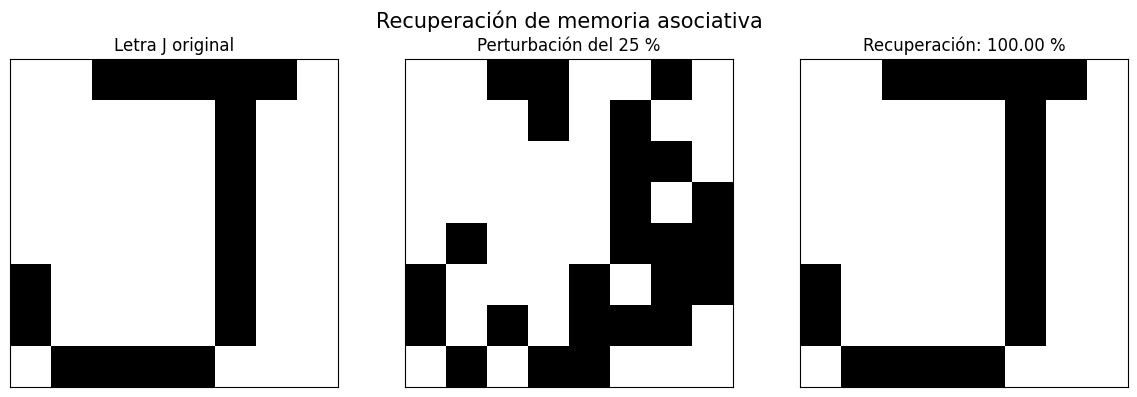

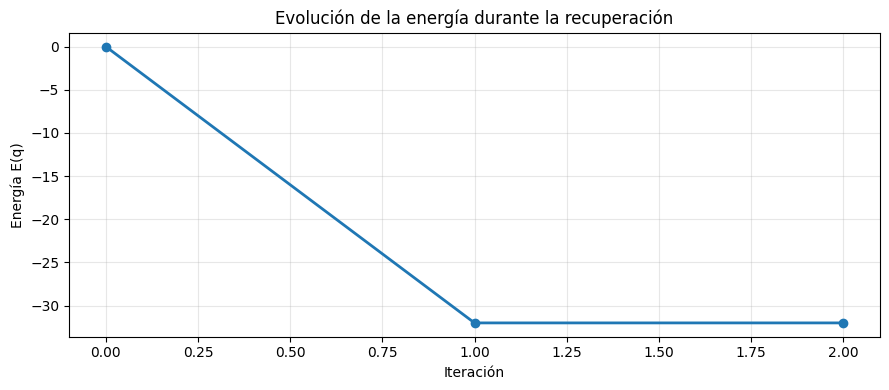


¿La energía es no creciente? True


In [3]:

# ============================================================
# 1. FUNCIÓN PARA PERTURBAR UN PATRÓN
# ============================================================

def perturbar_patron(patron, porcentaje, rng):
    """
    Invierte aleatoriamente un porcentaje de los píxeles.

    porcentaje: valor entre 0 y 100.
    """
    patron = np.asarray(patron, dtype=float).copy()

    if not 0 <= porcentaje <= 100:
        raise ValueError("El porcentaje debe estar entre 0 y 100.")

    N = patron.size
    n_errores = int(round(N * porcentaje / 100))

    indices = rng.choice(
        N, size=n_errores, replace=False
    )

    patron[indices] *= -1

    return patron


# ============================================================
# 2. FUNCIÓN DE RECUPERACIÓN ITERATIVA
# ============================================================

def recuperar_patron(
    q_inicial, X, beta=1.0, alpha=1.0,
    max_iter=100, tolerancia=1e-10
):
    """
    Recupera un patrón mediante descenso de gradiente.

    Devuelve el estado final y los historiales.
    """
    q = np.asarray(q_inicial, dtype=float).copy()

    historial_estados = [q.copy()]
    historial_energia = [energia(q, X, beta)]
    historial_cambios = []

    for iteracion in range(max_iter):

        q_nuevo = actualizar_estado(
            q, X, beta, alpha
        )

        cambio = np.linalg.norm(q_nuevo - q)

        historial_cambios.append(cambio)
        historial_estados.append(q_nuevo.copy())
        historial_energia.append(
            energia(q_nuevo, X, beta)
        )

        q = q_nuevo

        if cambio < tolerancia:
            break

    return {
        "estado_final": q,
        "estados": np.array(historial_estados),
        "energias": np.array(historial_energia),
        "cambios": np.array(historial_cambios),
        "iteraciones": len(historial_cambios)
    }


# ============================================================
# 3. CONVERSIÓN DEL ESTADO CONTINUO A BINARIO
# ============================================================

def convertir_binario(q):
    return np.where(np.asarray(q) >= 0, 1, -1)


def exactitud_recuperacion(original, recuperado):
    return 100 * np.mean(
        np.asarray(original) == np.asarray(recuperado)
    )


# ============================================================
# 4. GENERAR UNA LETRA J PERTURBADA
# ============================================================

rng = np.random.default_rng(42)

patron_original = J_vector.copy()

porcentaje_ruido = 25
beta = 1.0

patron_perturbado = perturbar_patron(
    patron_original, porcentaje_ruido, rng
)

# ============================================================
# 5. RECUPERAR LA MEMORIA
# ============================================================

resultado = recuperar_patron(
    patron_perturbado,
    X,
    beta=beta,
    alpha=1.0,
    max_iter=100,
    tolerancia=1e-10
)

estado_final = resultado["estado_final"]

patron_recuperado = convertir_binario(
    estado_final
)

exactitud_inicial = exactitud_recuperacion(
    patron_original, patron_perturbado
)

exactitud_final = exactitud_recuperacion(
    patron_original, patron_recuperado
)

# ============================================================
# 6. RESULTADOS NUMÉRICOS
# ============================================================

print("RECUPERACIÓN DE LA LETRA J")
print("=" * 48)
print(f"Perturbación aplicada: {porcentaje_ruido} %")
print(f"Parámetro beta: {beta}")
print(f"Iteraciones realizadas: {resultado['iteraciones']}")
print(f"Exactitud inicial: {exactitud_inicial:.2f} %")
print(f"Exactitud final: {exactitud_final:.2f} %")
print(f"Energía inicial: {resultado['energias'][0]:.8f}")
print(f"Energía final: {resultado['energias'][-1]:.8f}")

# ============================================================
# 7. VISUALIZACIÓN DE LOS PATRONES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

patrones = [
    patron_original,
    patron_perturbado,
    patron_recuperado
]

titulos = [
    "Letra J original",
    f"Perturbación del {porcentaje_ruido} %",
    f"Recuperación: {exactitud_final:.2f} %"
]

for ax, patron, titulo in zip(
    axes, patrones, titulos
):
    ax.imshow(
        patron.reshape(8, 8),
        cmap="gray_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    "Recuperación de memoria asociativa",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. EVOLUCIÓN DE LA ENERGÍA
# ============================================================

plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(len(resultado["energias"])),
    resultado["energias"],
    marker="o",
    linewidth=2
)

plt.xlabel("Iteración")
plt.ylabel("Energía E(q)")
plt.title("Evolución de la energía durante la recuperación")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Verificar que la energía no aumenta
diferencias_energia = np.diff(resultado["energias"])

print(
    "\n¿La energía es no creciente?",
    np.all(diferencias_energia <= 1e-9)
)



## 4. Análisis de robustez frente a diferentes perturbaciones

Para estudiar la capacidad de recuperación de la red, se realizarán múltiples experimentos utilizando diferentes porcentajes de píxeles invertidos.

Se evaluarán ambas memorias almacenadas, J y H, con perturbaciones del 0 % al 60 %. Para cada porcentaje se generarán 100 perturbaciones aleatorias independientes.

En cada ensayo se aplicará la regla de actualización con $\alpha=1$ y $\beta=1$, utilizando el mismo criterio de convergencia.

Se calcularán dos indicadores:

**Exactitud media de recuperación:**

$$
A(p)=\frac{1}{M}\sum_{k=1}^{M}
\left[
\frac{100}{N}\sum_{i=1}^{N}
\mathbb{I}(\hat{x}_i^{(k)}=x_i)
\right].
$$

**Tasa de recuperación perfecta:**

$$
R(p)=\frac{100}{M}
\sum_{k=1}^{M}
\mathbb{I}(\hat{\mathbf{x}}^{(k)}=\mathbf{x}).
$$

La primera métrica mide el porcentaje promedio de píxeles recuperados correctamente, mientras que la segunda indica en qué proporción de los ensayos se reconstruyó exactamente el patrón original.

Este análisis permitirá identificar cómo disminuye la calidad de recuperación a medida que aumenta la perturbación y comparar la robustez de ambas memorias.


RESULTADOS DE ROBUSTEZ


,Patrón,Perturbación (%),Exactitud media (%),Recuperación perfecta (%),Iteraciones medias
0,J,0,100.000,100.0,1.00
1,J,5,100.000,100.0,2.00
2,J,10,100.000,100.0,2.00
3,J,15,100.000,100.0,2.00
4,J,20,100.000,100.0,2.00
5,J,25,100.000,100.0,2.04
6,J,30,100.000,100.0,2.39
7,J,35,99.484,99.0,2.70
8,J,40,97.938,96.0,2.91
9,J,45,89.172,79.0,3.00


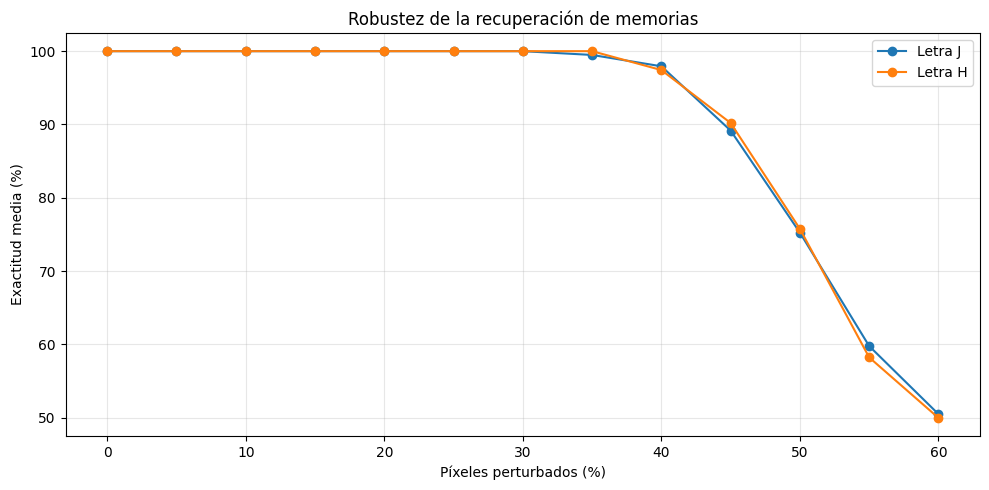

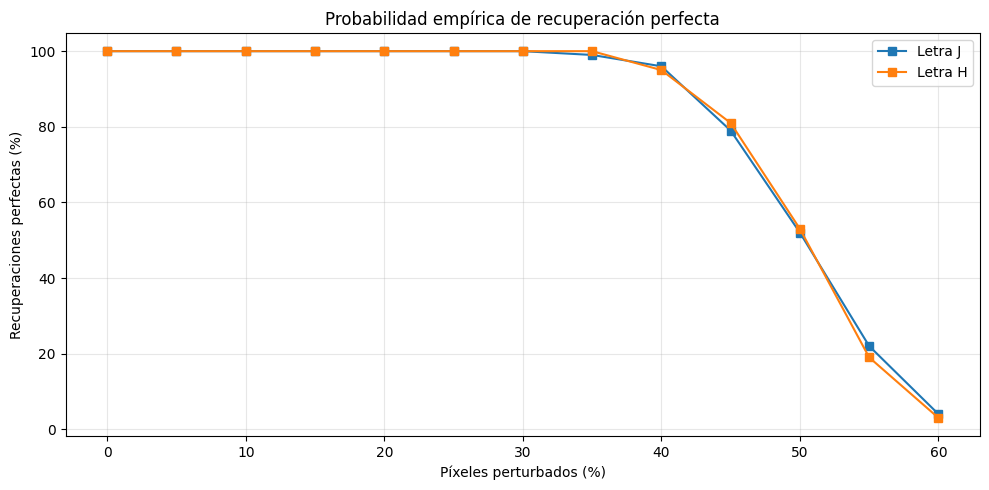

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración experimental
porcentajes = np.arange(0, 65, 5)
n_ensayos = 100
beta_robustez = 1.0

rng_robustez = np.random.default_rng(2026)

patrones = {
    "J": J_vector,
    "H": H_vector
}

registros = []

for nombre, original in patrones.items():
    for porcentaje in porcentajes:

        exactitudes = []
        recuperaciones_perfectas = []
        iteraciones = []

        for ensayo in range(n_ensayos):

            perturbado = perturbar_patron(
                original,
                porcentaje,
                rng_robustez
            )

            resultado_ensayo = recuperar_patron(
                perturbado,
                X,
                beta=beta_robustez,
                alpha=1.0,
                max_iter=100,
                tolerancia=1e-10
            )

            recuperado = convertir_binario(
                resultado_ensayo["estado_final"]
            )

            exactitud = exactitud_recuperacion(
                original,
                recuperado
            )

            exactitudes.append(exactitud)

            recuperaciones_perfectas.append(
                np.array_equal(recuperado, original)
            )

            iteraciones.append(
                resultado_ensayo["iteraciones"]
            )

        registros.append({
            "Patrón": nombre,
            "Perturbación (%)": porcentaje,
            "Exactitud media (%)": np.mean(exactitudes),
            "Recuperación perfecta (%)":
                100 * np.mean(recuperaciones_perfectas),
            "Iteraciones medias": np.mean(iteraciones)
        })

tabla_robustez = pd.DataFrame(registros)

print("RESULTADOS DE ROBUSTEZ")
display(tabla_robustez.round(3))

# Gráfica de exactitud media
plt.figure(figsize=(10, 5))

for nombre in patrones:
    datos = tabla_robustez[
        tabla_robustez["Patrón"] == nombre
    ]

    plt.plot(
        datos["Perturbación (%)"],
        datos["Exactitud media (%)"],
        marker="o",
        label=f"Letra {nombre}"
    )

plt.xlabel("Píxeles perturbados (%)")
plt.ylabel("Exactitud media (%)")
plt.title("Robustez de la recuperación de memorias")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfica de recuperación perfecta
plt.figure(figsize=(10, 5))

for nombre in patrones:
    datos = tabla_robustez[
        tabla_robustez["Patrón"] == nombre
    ]

    plt.plot(
        datos["Perturbación (%)"],
        datos["Recuperación perfecta (%)"],
        marker="s",
        label=f"Letra {nombre}"
    )

plt.xlabel("Píxeles perturbados (%)")
plt.ylabel("Recuperaciones perfectas (%)")
plt.title("Probabilidad empírica de recuperación perfecta")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Influencia del parámetro beta en la recuperación

El parámetro $\beta$ controla la selectividad de la memoria asociativa. Su efecto se estudia comparando la evolución de la energía y los estados finales obtenidos para diferentes valores de $\beta$.

Se utilizará una misma perturbación de la letra J para todos los experimentos, evitando que las diferencias observadas se deban a distintas realizaciones aleatorias.

Los valores estudiados serán:

$$
\beta\in\{0.001,\;0.01,\;0.05,\;0.1,\;0.5,\;1,\;2,\;5\}.
$$

Para cada valor se registrarán la energía inicial, la energía final, el número de iteraciones, la exactitud de recuperación y los pesos asociados a las memorias J y H.

Es importante tener en cuenta que la propia función de energía depende de $\beta$. Por tanto, las curvas correspondientes a distintos valores de este parámetro representan funciones de energía diferentes. La comparación más significativa consiste en analizar cómo disminuye cada energía respecto a su valor inicial.

Este experimento permitirá establecer cómo cambia la selectividad de la red y si los patrones almacenados se recuperan correctamente.


INFLUENCIA DEL PARÁMETRO BETA


,Beta,Iteraciones,Exactitud (%),Peso J,Peso H,Energía inicial,Energía final,Cambio de energía
0,0.001,9,100.0,0.500000,0.500000,-674.327670,-708.647181,-34.319511
1,0.010,23,100.0,0.500000,0.500000,-52.108961,-84.814718,-32.705757
2,0.050,22,100.0,0.951726,0.048274,-2.787735,-32.835750,-30.048015
3,0.100,8,100.0,0.998616,0.001384,-0.221242,-32.013718,-31.792476
4,0.500,3,100.0,1.000000,0.000000,-0.000000,-32.000000,-32.000000
5,1.000,2,100.0,1.000000,0.000000,0.000000,-32.000000,-32.000000
6,2.000,2,100.0,1.000000,0.000000,0.000000,-32.000000,-32.000000
7,5.000,2,100.0,1.000000,0.000000,0.000000,-32.000000,-32.000000


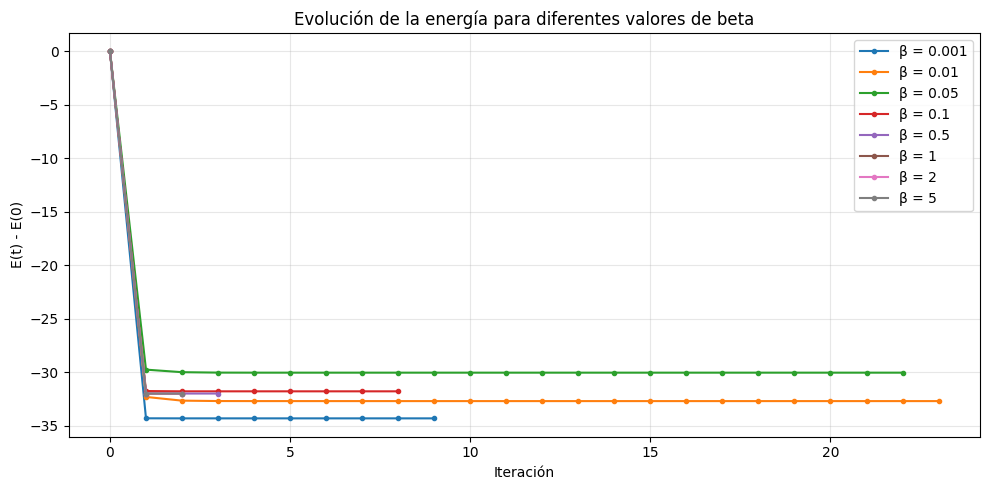

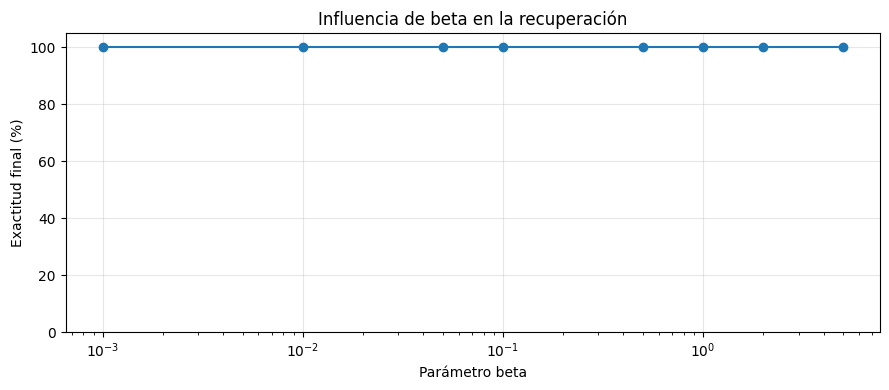

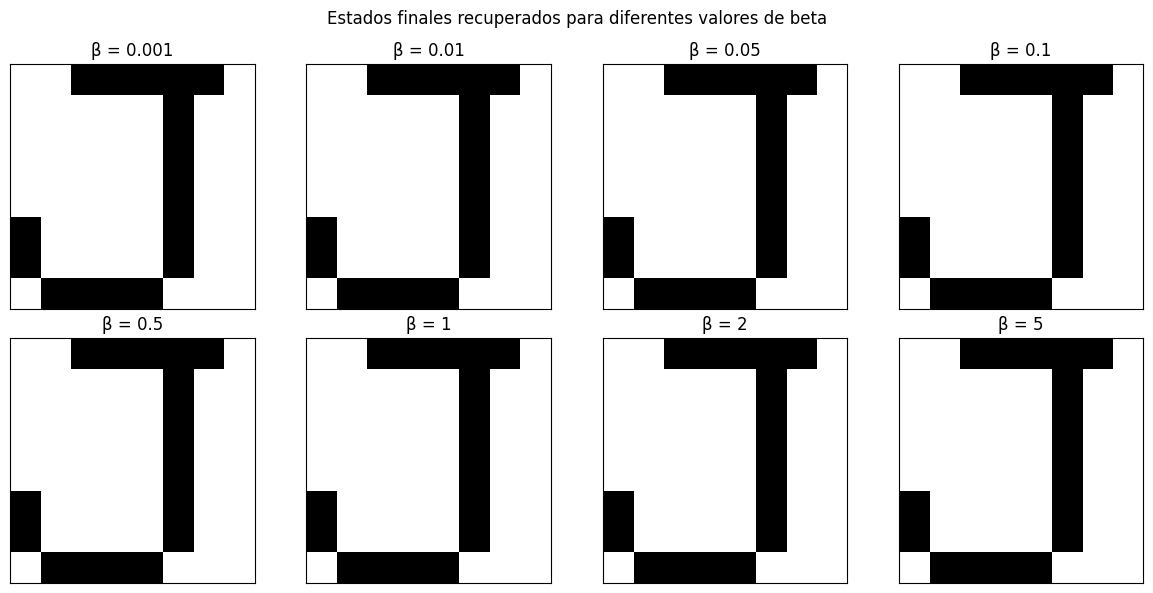

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Valores de beta
valores_beta = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5]

# Una misma perturbación para todos los beta
rng_beta = np.random.default_rng(123)

original_beta = J_vector.copy()

perturbado_beta = perturbar_patron(
    original_beta,
    porcentaje=25,
    rng=rng_beta
)

resultados_beta = []
historiales_beta = {}
estados_finales_beta = {}

for beta_actual in valores_beta:

    resultado_beta = recuperar_patron(
        perturbado_beta,
        X,
        beta=beta_actual,
        alpha=1.0,
        max_iter=100,
        tolerancia=1e-10
    )

    q_final = resultado_beta["estado_final"]
    patron_final = convertir_binario(q_final)

    pesos_finales = calcular_pesos(
        q_final, X, beta_actual
    )

    exactitud = exactitud_recuperacion(
        original_beta,
        patron_final
    )

    energias = resultado_beta["energias"]

    resultados_beta.append({
        "Beta": beta_actual,
        "Iteraciones": resultado_beta["iteraciones"],
        "Exactitud (%)": exactitud,
        "Peso J": pesos_finales[0],
        "Peso H": pesos_finales[1],
        "Energía inicial": energias[0],
        "Energía final": energias[-1],
        "Cambio de energía": energias[-1] - energias[0]
    })

    historiales_beta[beta_actual] = energias
    estados_finales_beta[beta_actual] = patron_final

tabla_beta = pd.DataFrame(resultados_beta)

print("INFLUENCIA DEL PARÁMETRO BETA")
display(tabla_beta.round(6))

# =====================================================
# 1. CAMBIO DE ENERGÍA RESPECTO AL VALOR INICIAL
# =====================================================

plt.figure(figsize=(10, 5))

for beta_actual, energias in historiales_beta.items():

    cambio_energia = energias - energias[0]

    plt.plot(
        np.arange(len(energias)),
        cambio_energia,
        marker="o",
        markersize=3,
        label=f"β = {beta_actual}"
    )

plt.xlabel("Iteración")
plt.ylabel("E(t) - E(0)")
plt.title("Evolución de la energía para diferentes valores de beta")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# 2. EXACTITUD FINAL SEGÚN BETA
# =====================================================

plt.figure(figsize=(9, 4))

plt.semilogx(
    tabla_beta["Beta"],
    tabla_beta["Exactitud (%)"],
    marker="o"
)

plt.xlabel("Parámetro beta")
plt.ylabel("Exactitud final (%)")
plt.title("Influencia de beta en la recuperación")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# 3. VISUALIZACIÓN DE LOS ESTADOS FINALES
# =====================================================

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, beta_actual in zip(axes.flat, valores_beta):

    patron = estados_finales_beta[beta_actual]

    ax.imshow(
        patron.reshape(8, 8),
        cmap="gray_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(f"β = {beta_actual}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    "Estados finales recuperados para diferentes valores de beta"
)

plt.tight_layout()
plt.show()



### 5.1. Análisis de la selectividad y del estado continuo

La exactitud binaria alcanzó el 100 % para todos los valores de $\beta$ evaluados. Sin embargo, esta métrica no permite distinguir completamente los estados continuos de la red.

Para complementar el análisis se calcula la distancia euclidiana normalizada entre el estado final y el patrón original:

$$
d(\mathbf q,\mathbf x^J)=
\frac{\|\mathbf q-\mathbf x^J\|_2}{\sqrt N}.
$$

También se representan los pesos de recuperación $p_J$ y $p_H$.

De esta manera se podrá observar cómo influye $\beta$ en la selectividad de la memoria, incluso cuando todos los experimentos producen la misma reconstrucción binaria.


SELECTIVIDAD Y PRECISIÓN CONTINUA


,Beta,Exactitud (%),Peso J,Peso H,Distancia continua
0,0.001,100.0,0.500000,0.500000,0.718070
1,0.010,100.0,0.500000,0.500000,0.718070
2,0.050,100.0,0.951727,0.048273,0.069328
3,0.100,100.0,0.998616,0.001384,0.001987
4,0.500,100.0,1.000000,0.000000,0.000000
5,1.000,100.0,1.000000,0.000000,0.000000
6,2.000,100.0,1.000000,0.000000,0.000000
7,5.000,100.0,1.000000,0.000000,0.000000


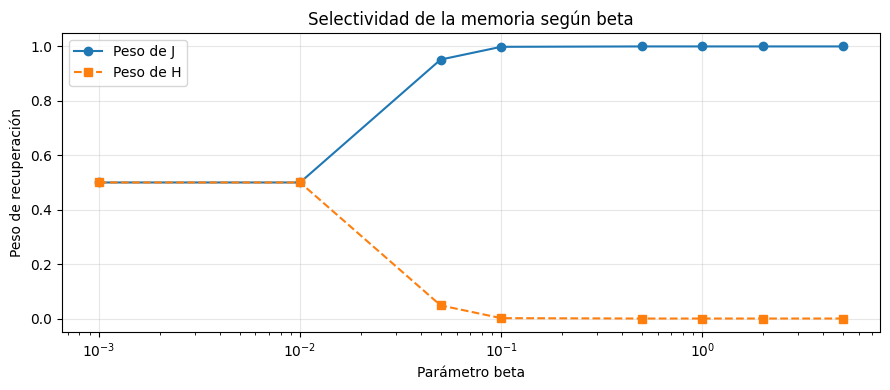

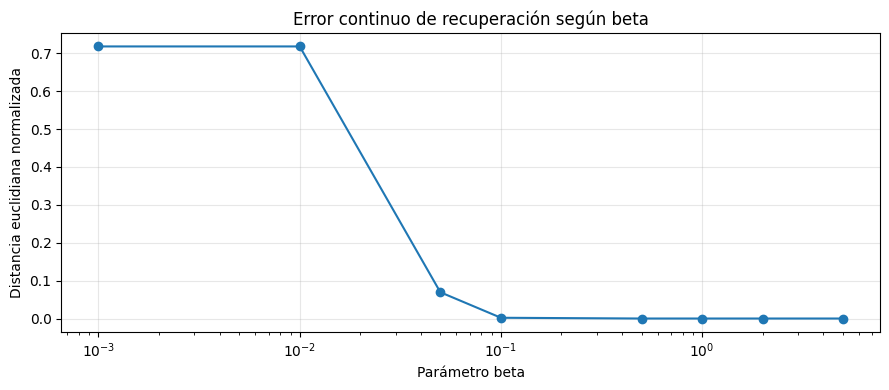

In [6]:

# Calcular distancia continua para cada beta
distancias = []

for beta_actual in valores_beta:

    # Recuperamos el estado continuo ejecutando nuevamente
    # el experimento con la misma entrada perturbada
    resultado_actual = recuperar_patron(
        perturbado_beta,
        X,
        beta=beta_actual,
        alpha=1.0,
        max_iter=100,
        tolerancia=1e-10
    )

    q_final = resultado_actual["estado_final"]

    distancia = (
        np.linalg.norm(q_final - original_beta)
        / np.sqrt(N)
    )

    distancias.append(distancia)

tabla_beta["Distancia continua"] = distancias

print("SELECTIVIDAD Y PRECISIÓN CONTINUA")
display(
    tabla_beta[
        ["Beta", "Exactitud (%)", "Peso J",
         "Peso H", "Distancia continua"]
    ].round(8)
)

# Pesos de recuperación
plt.figure(figsize=(9, 4))

plt.semilogx(
    tabla_beta["Beta"],
    tabla_beta["Peso J"],
    "o-",
    label="Peso de J"
)

plt.semilogx(
    tabla_beta["Beta"],
    tabla_beta["Peso H"],
    "s--",
    label="Peso de H"
)

plt.xlabel("Parámetro beta")
plt.ylabel("Peso de recuperación")
plt.title("Selectividad de la memoria según beta")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Distancia al patrón original
plt.figure(figsize=(9, 4))

plt.semilogx(
    tabla_beta["Beta"],
    tabla_beta["Distancia continua"],
    "o-"
)

plt.xlabel("Parámetro beta")
plt.ylabel("Distancia euclidiana normalizada")
plt.title("Error continuo de recuperación según beta")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### 5.2. Discusión de los resultados: influencia de beta

Los experimentos muestran que el parámetro $\beta$ influye directamente en la selectividad de la memoria asociativa.

Para valores pequeños de $\beta$, los pesos asociados a las letras J y H son aproximadamente iguales. Esto significa que la red produce una combinación de ambas memorias, en lugar de seleccionar claramente una de ellas.

Al aumentar $\beta$, el peso correspondiente a J crece rápidamente y se aproxima a uno, mientras que el peso de H tiende a cero. Por tanto, la red se vuelve más selectiva y el estado continuo se aproxima al patrón almacenado.

Aunque la exactitud binaria alcanzó el 100 % para todos los valores evaluados, este resultado no significa que los estados continuos sean iguales. La conversión mediante la función signo puede producir la misma imagen binaria a partir de combinaciones diferentes de las memorias.

Por esta razón, es necesario complementar la exactitud binaria con los pesos de recuperación y la distancia continua al patrón original.

En conjunto, los resultados muestran que $\beta$ controla la intensidad con la que la red favorece la memoria más similar al estado de entrada.



## 6. Conclusiones generales

En este trabajo se implementó una red de memoria asociativa formada por 64 neuronas, capaz de almacenar dos patrones binarios correspondientes a las letras J y H.

A partir de la función de energía propuesta, se obtuvo analíticamente el gradiente y se implementó una regla de actualización basada en descenso de gradiente con un paso de aprendizaje igual a uno.

Los experimentos demostraron que la red puede recuperar información almacenada incluso cuando el patrón inicial contiene errores. Para una perturbación del 25 % de los píxeles de la letra J, se obtuvo una recuperación binaria del 100 %.

El estudio de robustez mostró que la red mantiene una exactitud muy alta para perturbaciones pequeñas y moderadas. Sin embargo, al aumentar el porcentaje de píxeles invertidos, la calidad de recuperación disminuye, debido a que el estado inicial puede perder similitud con la memoria original.

También se estudió la influencia del parámetro beta. Los resultados mostraron que, para valores pequeños, la red combina las memorias almacenadas con pesos similares, mientras que para valores mayores concentra progresivamente la recuperación en el patrón más parecido a la entrada.

Aunque la exactitud binaria fue del 100 % para todos los valores de beta considerados en un experimento con una perturbación fija, el análisis de la distancia euclidiana normalizada reveló diferencias importantes entre los estados continuos. Esto demuestra que la exactitud binaria no es suficiente por sí sola para evaluar la calidad de la recuperación.

En conclusión, la red de memoria asociativa implementada reproduce el mecanismo de recuperación basado en energía y evidencia la importancia de la similitud entre patrones, la intensidad de las perturbaciones y la selectividad controlada por beta.

El ejercicio muestra cómo una dinámica matemática relativamente sencilla puede recuperar información incompleta o alterada, proporcionando un ejemplo concreto de la relación entre optimización, memoria asociativa y mecanismos de atención.



## 7. Verificación final de los numerales (a) y (c)

### 7.1. Representación continua y binaria de los patrones

En el numeral (a) se solicita visualizar el patrón original, el patrón perturbado y el estado recuperado, tanto en su representación continua como binaria.

La red evoluciona mediante estados continuos:

$$
\mathbf q^{(t)}\in\mathbb R^{64}.
$$

Para obtener la representación binaria del estado final se utiliza:

$$
\hat{x}_i=
\begin{cases}
+1, & q_i\geq 0,\\
-1, & q_i<0.
\end{cases}
$$

La representación continua permite observar los valores reales de las neuronas, mientras que la binaria permite determinar si se recuperó correctamente la imagen almacenada.

Se mostrarán ambas representaciones para una letra J perturbada en el 25 % de sus píxeles.

### 7.2. Evolución de la energía para diferentes valores de beta

En el numeral (c) se estudia cómo el parámetro $\beta$ modifica la evolución de la energía y los estados finales.

La función de energía es:

$$
E_\beta(\mathbf q)=
\frac12\|\mathbf q\|^2-
\frac1\beta\log\left(
\sum_{\mu=1}^{P}
e^{\beta\mathbf x^\mu\cdot\mathbf q}
\right).
$$

Se evaluará la evolución de $E_\beta$ para diferentes valores de $\beta$, utilizando el mismo patrón perturbado como condición inicial.

Como la función de energía depende de $\beta$, se representará tanto la energía absoluta como su variación respecto al valor inicial:

$$
\Delta E_\beta(t)=
E_\beta(\mathbf q^{(t)})
-
E_\beta(\mathbf q^{(0)}).
$$

Esto permitirá comprobar si la energía disminuye durante la recuperación y relacionar dicho comportamiento con la selectividad de las memorias almacenadas.


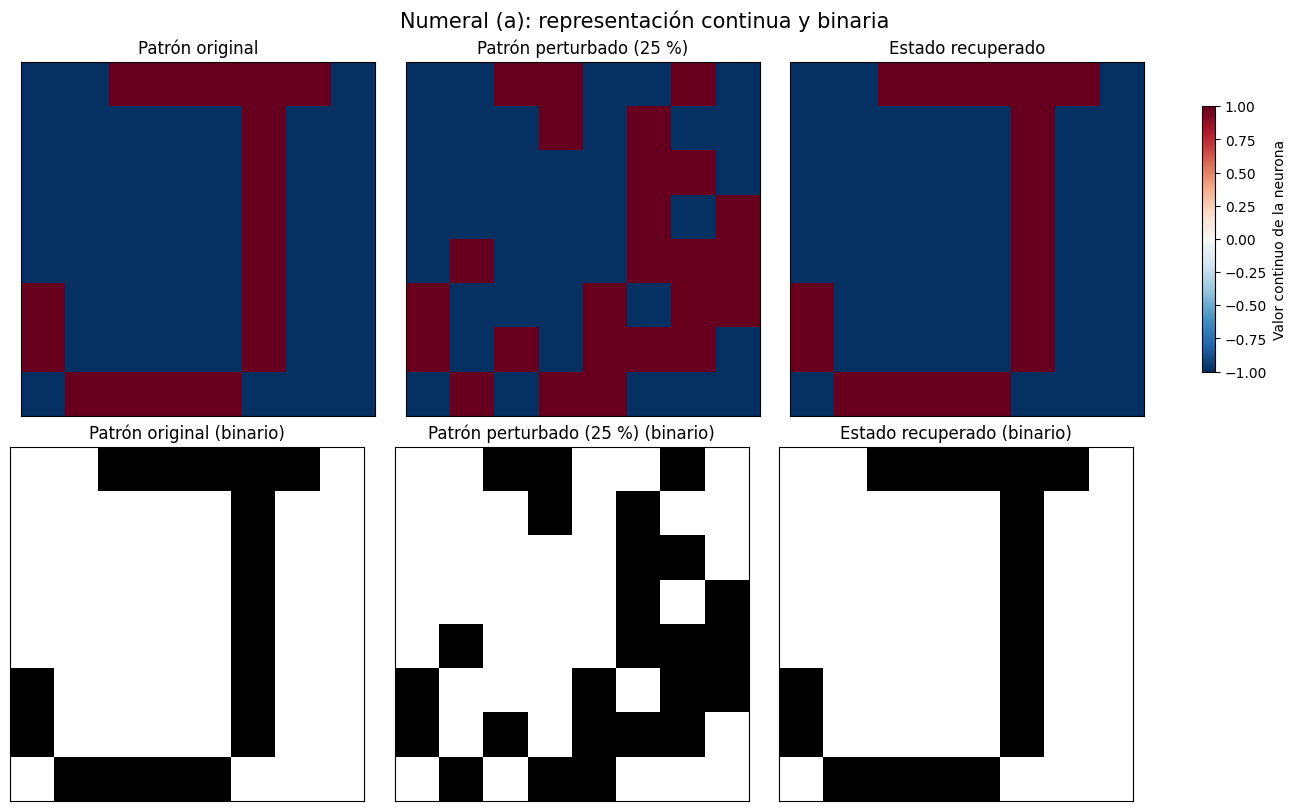

NUMERAL (a): RESULTADOS
------------------------------------------------
Exactitud inicial: 75.00 %
Exactitud final: 100.00 %
Distancia continua normalizada: 0.00000000e+00


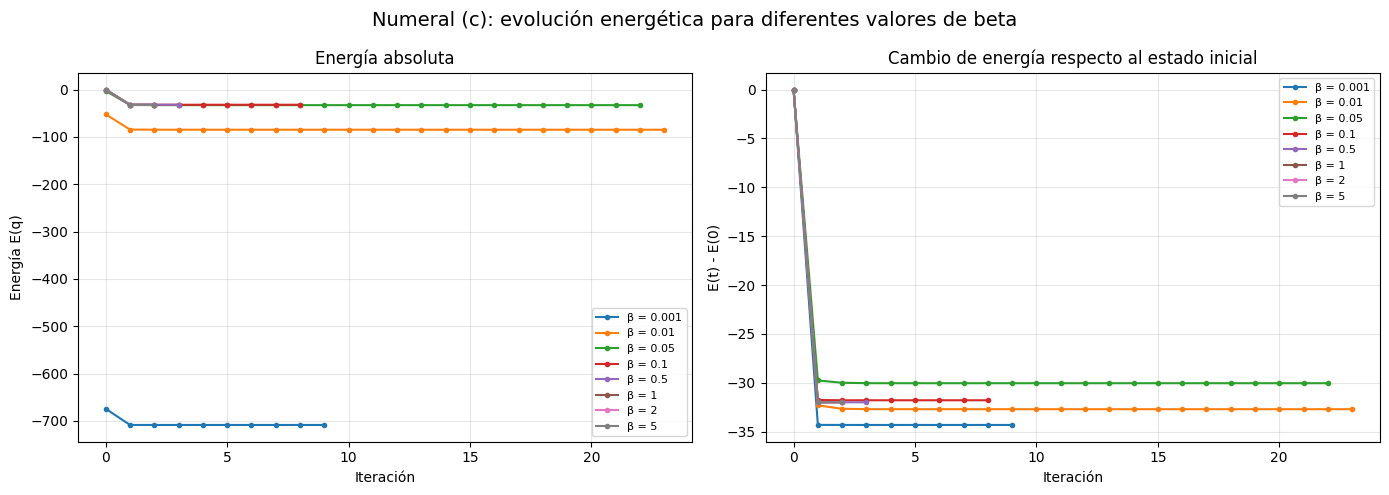


NUMERAL (c): VERIFICACIÓN ENERGÉTICA
    Beta      E inicial        E final        Delta E   No aumenta
   0.001    -674.327670    -708.647181     -34.319511         True
   0.010     -52.108961     -84.814718     -32.705757         True
   0.050      -2.787735     -32.835750     -30.048015         True
   0.100      -0.221242     -32.013718     -31.792476         True
   0.500      -0.000000     -32.000000     -32.000000         True
   1.000       0.000000     -32.000000     -32.000000         True
   2.000       0.000000     -32.000000     -32.000000         True
   5.000       0.000000     -32.000000     -32.000000         True

Verificación final completada.


In [7]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# NUMERAL (a): REPRESENTACIÓN CONTINUA Y BINARIA
# ============================================================

# Utilizamos el experimento de recuperación de la letra J
original = patron_original.copy()
perturbado = patron_perturbado.copy()
continuo_final = resultado["estado_final"].copy()
binario_final = convertir_binario(continuo_final)

estados = [
    original,
    perturbado,
    continuo_final
]

titulos = [
    "Patrón original",
    "Patrón perturbado (25 %)",
    "Estado recuperado"
]

fig, axes = plt.subplots(
    2, 3, figsize=(13, 8),
    constrained_layout=True
)

# Fila superior: valores continuos
for j, (estado, titulo) in enumerate(zip(estados, titulos)):
    imagen = axes[0, j].imshow(
        estado.reshape(8, 8),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    axes[0, j].set_title(titulo)
    axes[0, j].set_xticks([])
    axes[0, j].set_yticks([])

fig.colorbar(
    imagen,
    ax=axes[0, :],
    shrink=0.75,
    label="Valor continuo de la neurona"
)

# Fila inferior: representación binaria
for j, (estado, titulo) in enumerate(zip(estados, titulos)):
    binario = convertir_binario(estado)

    axes[1, j].imshow(
        binario.reshape(8, 8),
        cmap="gray_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    axes[1, j].set_title(titulo + " (binario)")
    axes[1, j].set_xticks([])
    axes[1, j].set_yticks([])

fig.suptitle(
    "Numeral (a): representación continua y binaria",
    fontsize=15
)

plt.show()

print("NUMERAL (a): RESULTADOS")
print("-" * 48)
print(
    "Exactitud inicial:",
    f"{exactitud_recuperacion(original, perturbado):.2f} %"
)
print(
    "Exactitud final:",
    f"{exactitud_recuperacion(original, binario_final):.2f} %"
)
print(
    "Distancia continua normalizada:",
    f"{np.linalg.norm(continuo_final-original)/np.sqrt(N):.8e}"
)

# ============================================================
# NUMERAL (c): EVOLUCIÓN DE LA ENERGÍA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for beta_actual in valores_beta:

    energias = historiales_beta[beta_actual]
    iteraciones = np.arange(len(energias))

    axes[0].plot(
        iteraciones,
        energias,
        marker="o",
        markersize=3,
        label=f"β = {beta_actual}"
    )

    axes[1].plot(
        iteraciones,
        energias - energias[0],
        marker="o",
        markersize=3,
        label=f"β = {beta_actual}"
    )

axes[0].set_title("Energía absoluta")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("Energía E(q)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title("Cambio de energía respecto al estado inicial")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("E(t) - E(0)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

plt.suptitle(
    "Numeral (c): evolución energética para diferentes valores de beta",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ============================================================
# VERIFICACIÓN NUMÉRICA DEL DESCENSO DE ENERGÍA
# ============================================================

print("\nNUMERAL (c): VERIFICACIÓN ENERGÉTICA")
print("=" * 68)

print(
    f"{'Beta':>8} {'E inicial':>14} "
    f"{'E final':>14} {'Delta E':>14} {'No aumenta':>12}"
)

for beta_actual in valores_beta:

    energias = historiales_beta[beta_actual]

    E_inicial = energias[0]
    E_final = energias[-1]
    delta_E = E_final - E_inicial

    no_aumenta = np.all(
        np.diff(energias) <= 1e-9
    )

    print(
        f"{beta_actual:8.3f} "
        f"{E_inicial:14.6f} "
        f"{E_final:14.6f} "
        f"{delta_E:14.6f} "
        f"{str(no_aumenta):>12}"
    )

print("\nVerificación final completada.")



## 8. Recuperación de la segunda memoria almacenada: letra H

Después de estudiar la recuperación de la letra J, se realiza el mismo procedimiento con la letra H para comprobar que la red puede recuperar ambos patrones almacenados.

Se utiliza una perturbación aleatoria del 25 % de sus 64 píxeles, equivalente a invertir 16 componentes del patrón original.

La condición inicial es:

$$
\mathbf q^{(0)}=\tilde{\mathbf x}^{H},
$$

donde $\tilde{\mathbf x}^{H}$ representa la letra H perturbada.

La evolución se calcula mediante:

$$
\mathbf q^{(t+1)}
=
X^\mathsf{T}
\operatorname{softmax}
\left(\beta X\mathbf q^{(t)}\right),
$$

con $\alpha=1$ y $\beta=1$.

Se visualizarán el patrón original, el patrón perturbado y el estado recuperado, tanto en representación continua como binaria.

También se calcularán la exactitud inicial, la exactitud final, los pesos de recuperación y la evolución de la energía.

Este experimento permitirá verificar si la red reconoce y reconstruye correctamente la segunda memoria almacenada.


RECUPERACIÓN DE LA LETRA H
Perturbación: 25 %
Exactitud inicial: 75.00 %
Exactitud final: 100.00 %
Iteraciones: 2
Distancia continua: 0.00000000e+00
Peso de J: 0.00000000
Peso de H: 1.00000000
Energía inicial: -0.00000000
Energía final: -32.00000000


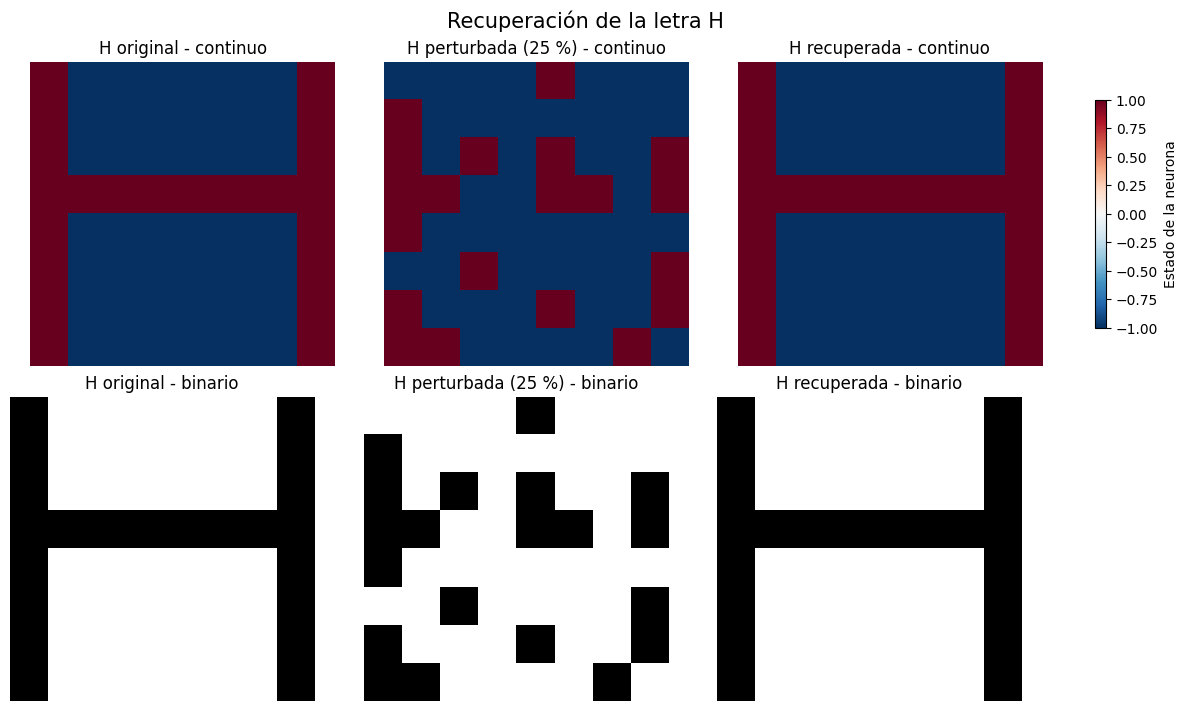

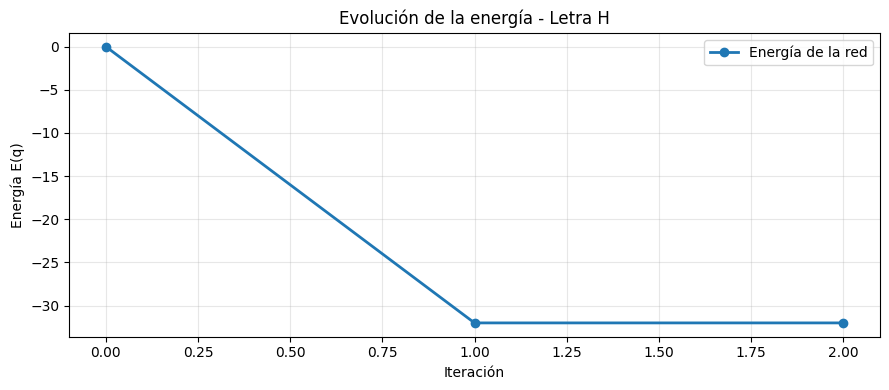


¿La energía no aumenta? True


In [8]:

# ============================================================
# RECUPERACIÓN DE LA LETRA H
# ============================================================

rng_H = np.random.default_rng(2027)

original_H = H_vector.copy()
porcentaje_H = 25
beta_H = 1.0

# 1. Perturbar 25 % de los píxeles
perturbado_H = perturbar_patron(
    original_H,
    porcentaje_H,
    rng_H
)

# 2. Recuperar el patrón
resultado_H = recuperar_patron(
    perturbado_H,
    X,
    beta=beta_H,
    alpha=1.0,
    max_iter=100,
    tolerancia=1e-10
)

continuo_H = resultado_H["estado_final"]
binario_H = convertir_binario(continuo_H)

# 3. Calcular métricas
exactitud_inicial_H = exactitud_recuperacion(
    original_H, perturbado_H
)

exactitud_final_H = exactitud_recuperacion(
    original_H, binario_H
)

distancia_H = (
    np.linalg.norm(continuo_H - original_H)
    / np.sqrt(N)
)

pesos_H = calcular_pesos(
    continuo_H, X, beta_H
)

# 4. Mostrar resultados
print("RECUPERACIÓN DE LA LETRA H")
print("=" * 55)
print(f"Perturbación: {porcentaje_H} %")
print(f"Exactitud inicial: {exactitud_inicial_H:.2f} %")
print(f"Exactitud final: {exactitud_final_H:.2f} %")
print(f"Iteraciones: {resultado_H['iteraciones']}")
print(f"Distancia continua: {distancia_H:.8e}")
print(f"Peso de J: {pesos_H[0]:.8f}")
print(f"Peso de H: {pesos_H[1]:.8f}")
print(f"Energía inicial: {resultado_H['energias'][0]:.8f}")
print(f"Energía final: {resultado_H['energias'][-1]:.8f}")

# ============================================================
# 5. VISUALIZACIÓN CONTINUA Y BINARIA
# ============================================================

estados_H = [
    original_H,
    perturbado_H,
    continuo_H
]

titulos_H = [
    "H original",
    "H perturbada (25 %)",
    "H recuperada"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7),
    constrained_layout=True
)

for j, (estado, titulo) in enumerate(
    zip(estados_H, titulos_H)
):
    im = axes[0, j].imshow(
        estado.reshape(8, 8),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )
    axes[0, j].set_title(titulo + " - continuo")
    axes[0, j].axis("off")

    axes[1, j].imshow(
        convertir_binario(estado).reshape(8, 8),
        cmap="gray_r",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )
    axes[1, j].set_title(titulo + " - binario")
    axes[1, j].axis("off")

fig.colorbar(
    im,
    ax=axes[0, :],
    shrink=0.75,
    label="Estado de la neurona"
)

plt.suptitle(
    "Recuperación de la letra H",
    fontsize=15
)
plt.show()

# ============================================================
# 6. EVOLUCIÓN DE LA ENERGÍA
# ============================================================

plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(len(resultado_H["energias"])),
    resultado_H["energias"],
    marker="o",
    linewidth=2,
    label="Energía de la red"
)

plt.xlabel("Iteración")
plt.ylabel("Energía E(q)")
plt.title("Evolución de la energía - Letra H")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "\n¿La energía no aumenta?",
    np.all(np.diff(resultado_H["energias"]) <= 1e-9)
)



## 9. Verificación de la evolución energética

Para completar el análisis de la red de memoria asociativa, se estudia la evolución de la energía durante la recuperación de las letras J y H.

La función de energía está definida por:

$$
E_\beta(\mathbf q)=
\frac12\|\mathbf q\|^2-
\frac1\beta\log\left(
\sum_{\mu=1}^{P}
e^{\beta\mathbf x^\mu\cdot\mathbf q}
\right).
$$

La dinámica de recuperación se implementa mediante:

$$
\mathbf q^{(t+1)}
=
X^\mathsf{T}
\operatorname{softmax}(\beta X\mathbf q^{(t)}).
$$

Para verificar el comportamiento energético se realizan dos análisis:

1. Comparar la evolución de la energía durante la recuperación de las letras J y H, utilizando una perturbación del 25 % y $\beta=1$.

2. Estudiar cómo cambia la evolución energética para diferentes valores de $\beta$, manteniendo fija la condición inicial perturbada.

Se verificará numéricamente que:

$$
E_\beta(\mathbf q^{(t+1)})
-
E_\beta(\mathbf q^{(t)})
\leq 0.
$$

Como cada valor de $\beta$ define una función de energía diferente, también se representará el cambio de energía respecto al valor inicial:

$$
\Delta E_\beta(t)=
E_\beta(\mathbf q^{(t)})
-
E_\beta(\mathbf q^{(0)}).
$$

Finalmente, se comprobará que las soluciones alcanzan estados estacionarios mediante la norma de la diferencia entre iteraciones consecutivas.


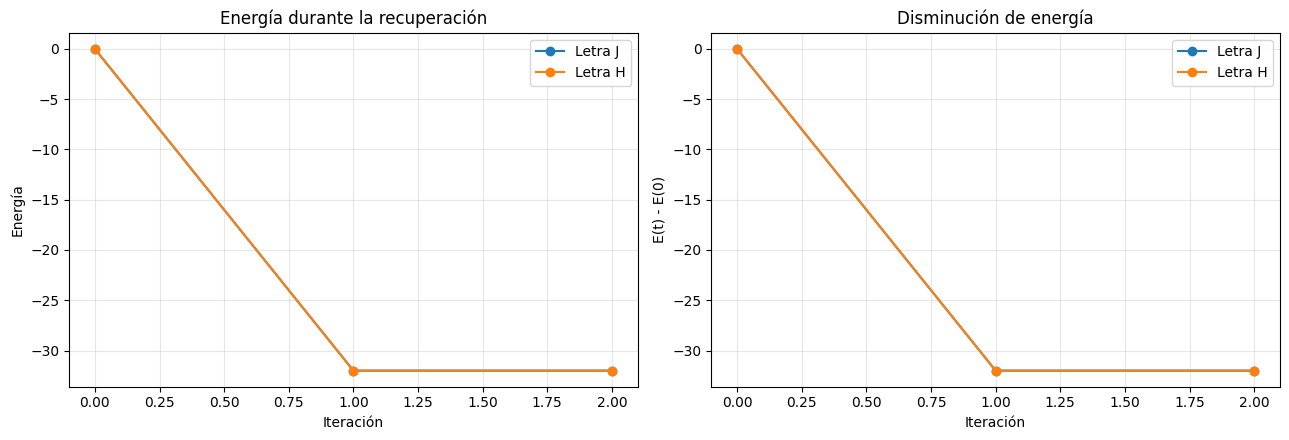

VERIFICACIÓN ENERGÉTICA DE J Y H

Letra J
Energía inicial: 0.0000000000
Energía final: -32.0000000000
Cambio energético: -32.0000000000
¿Energía no creciente?: True

Letra H
Energía inicial: -0.0000000000
Energía final: -32.0000000000
Cambio energético: -32.0000000000
¿Energía no creciente?: True


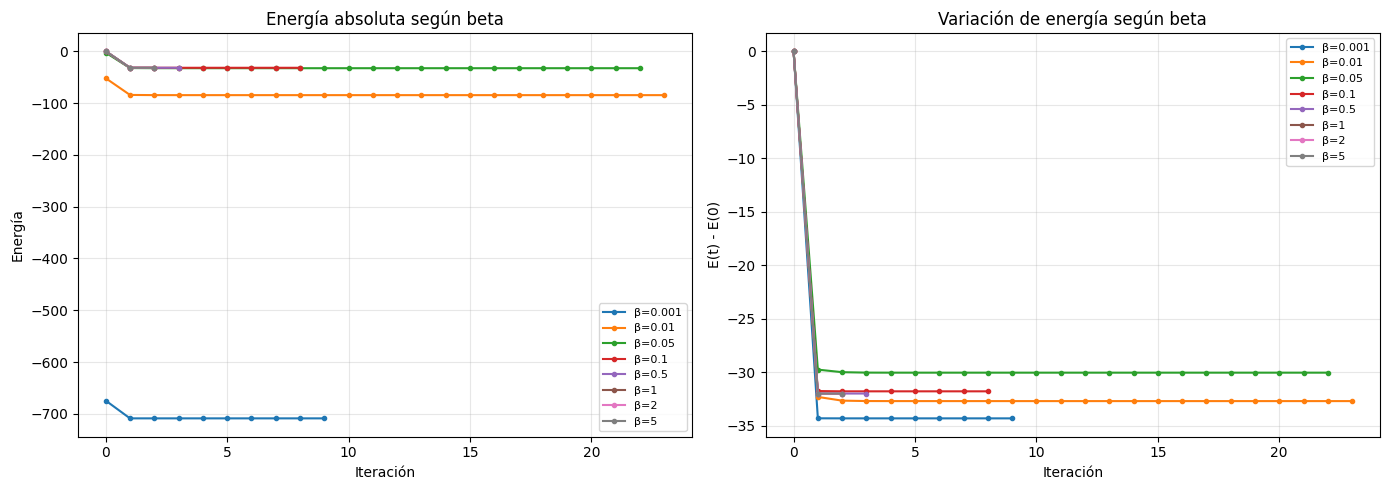


RESUMEN ENERGÉTICO PARA DIFERENTES BETA


,Beta,E inicial,E final,Cambio de energía,No creciente
0,0.001,-6.743277e+02,-708.647181,-34.319511,True
1,0.010,-5.210896e+01,-84.814718,-32.705757,True
2,0.050,-2.787735e+00,-32.835750,-30.048015,True
3,0.100,-2.212422e-01,-32.013718,-31.792476,True
4,0.500,-1.000000e-08,-32.000000,-32.000000,True
5,1.000,0.000000e+00,-32.000000,-32.000000,True
6,2.000,0.000000e+00,-32.000000,-32.000000,True
7,5.000,0.000000e+00,-32.000000,-32.000000,True



VERIFICACIÓN DE CONVERGENCIA
Letra J: iteraciones=2, último cambio=0.000e+00
Letra H: iteraciones=2, último cambio=5.870e-11

Análisis energético completado.


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. COMPARACIÓN ENERGÉTICA DE LAS LETRAS J Y H
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

experimentos = {
    "J": resultado,
    "H": resultado_H
}

for nombre, experimento in experimentos.items():

    energias = experimento["energias"]
    pasos = np.arange(len(energias))

    axes[0].plot(
        pasos, energias,
        marker="o", label=f"Letra {nombre}"
    )

    axes[1].plot(
        pasos, energias - energias[0],
        marker="o", label=f"Letra {nombre}"
    )

axes[0].set_title("Energía durante la recuperación")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("Energía")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Disminución de energía")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("E(t) - E(0)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 2. VERIFICACIÓN DE MONOTONICIDAD
# ============================================================

print("VERIFICACIÓN ENERGÉTICA DE J Y H")
print("=" * 70)

for nombre, experimento in experimentos.items():

    energias = experimento["energias"]
    diferencias = np.diff(energias)

    es_no_creciente = np.all(diferencias <= 1e-9)

    print(f"\nLetra {nombre}")
    print(f"Energía inicial: {energias[0]:.10f}")
    print(f"Energía final: {energias[-1]:.10f}")
    print(f"Cambio energético: {energias[-1]-energias[0]:.10f}")
    print(f"¿Energía no creciente?: {es_no_creciente}")

# ============================================================
# 3. EFECTO DE BETA SOBRE LA ENERGÍA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

filas = []

for beta_actual in valores_beta:

    energias = historiales_beta[beta_actual]
    pasos = np.arange(len(energias))
    diferencias = np.diff(energias)

    axes[0].plot(
        pasos, energias,
        marker="o", markersize=3,
        label=f"β={beta_actual}"
    )

    axes[1].plot(
        pasos, energias - energias[0],
        marker="o", markersize=3,
        label=f"β={beta_actual}"
    )

    filas.append({
        "Beta": beta_actual,
        "E inicial": energias[0],
        "E final": energias[-1],
        "Cambio de energía": energias[-1] - energias[0],
        "No creciente": np.all(diferencias <= 1e-9)
    })

axes[0].set_title("Energía absoluta según beta")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("Energía")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title("Variación de energía según beta")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("E(t) - E(0)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

tabla_energia = pd.DataFrame(filas)

print("\nRESUMEN ENERGÉTICO PARA DIFERENTES BETA")
display(tabla_energia.round(8))

# ============================================================
# 4. COMPROBACIÓN DE CONVERGENCIA
# ============================================================

print("\nVERIFICACIÓN DE CONVERGENCIA")
print("=" * 70)

for nombre, experimento in experimentos.items():

    cambios = experimento["cambios"]

    ultimo_cambio = cambios[-1] if len(cambios) else np.nan

    print(
        f"Letra {nombre}: "
        f"iteraciones={experimento['iteraciones']}, "
        f"último cambio={ultimo_cambio:.3e}"
    )

print("\nAnálisis energético completado.")


### 10. Conclusión general del punto 4

En este ejercicio se implementó una red de memoria asociativa formada por 64 neuronas, capaz de almacenar y recuperar dos patrones binarios correspondientes a las letras J y H.

A partir de la función de energía propuesta se obtuvo analíticamente el gradiente y se implementó una regla de actualización mediante descenso de gradiente con \(\alpha=1\).

Los resultados computacionales mostraron que la red pudo reconstruir correctamente ambas letras después de invertir aleatoriamente el 25 % de sus píxeles. En los dos casos se observó una recuperación binaria completa del patrón original.

El análisis de robustez permitió estudiar el comportamiento de la red frente a perturbaciones de diferente intensidad. Se encontró una recuperación muy alta para perturbaciones pequeñas y moderadas, mientras que para porcentajes mayores la exactitud disminuyó progresivamente.

También se comprobó que el parámetro \(\beta\) controla la selectividad de la memoria. Para valores pequeños, los patrones contribuyen con pesos similares, generando estados continuos que representan mezclas de las memorias. Para valores mayores, la red favorece claramente el patrón más similar y disminuye la distancia continua respecto a la memoria recuperada.

Finalmente, las gráficas de energía mostraron una disminución durante las iteraciones y una posterior estabilización, en concordancia con la dinámica de minimización utilizada.

En conjunto, los resultados muestran que una red de memoria asociativa basada en energía puede recuperar patrones alterados y que su desempeño depende tanto de la intensidad de la perturbación como de la selectividad determinada por \(\beta\). El ejercicio también evidencia la importancia de complementar la exactitud binaria con métricas continuas y análisis energéticos para evaluar adecuadamente la recuperación.